# 2025 top 1%: persistent and other recipients

How do persistent and other recipients differ within the 2025 top 1%?

**Scope:** Recipients qualifying in 2025 within the shared cohort, classified using their observed 2020-2025 membership. Amounts, requests and age refer to 2025; group counts use unique recipient codes.

This notebook compares persistent recipients with the remaining 2025 top-1% recipients. 'Other' includes both first-observed newcomers and recipients that qualified earlier without qualifying in every year. The filename retains the earlier wording, but the main comparison is not returning versus newcomer.

The [Methodology](../METHODOLOGY.md) documents definitions and correction policies. The [Project overview](../README.md) describes the notebook sequence and dataset rebuild process.

## Recipient-year data inputs

The inputs are the processed recipient-year table, including organization age, and the shared analysis helpers.

In [ ]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Locate the checkout from the project folder or a notebook subfolder.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "analysis_helpers.py").is_file()
     and (p / "config" / "sources.yaml").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the project folder.")
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from chart_style import apply_chart_style, colors_from_style, growth_cmap_from_style, load_chart_style

chart_style = load_chart_style(PROJECT_ROOT)
apply_chart_style(chart_style)
CHART_COLORS = colors_from_style(chart_style)
GROWTH_CMAP = growth_cmap_from_style(chart_style)
from analysis_helpers import (
    build_top_1_presence,
    build_top_1_streaks,
    prepare_top_1_dataset,
)
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Use the processed recipient-year analysis table because it includes reusable
# organization age fields created in the transformation pipeline.
vmi = pd.read_csv(PROCESSED_DIR / "recipient_analysis.csv", low_memory=False, dtype={"recipient_code": "string"})

vmi["tax_year"] = pd.to_numeric(vmi["tax_year"], errors="coerce")
vmi["recipient_code"] = vmi["recipient_code"].astype("string").str.strip()
vmi["requests"] = pd.to_numeric(vmi["requests"], errors="coerce")
vmi["calculated_pmd_eur"] = pd.to_numeric(vmi["calculated_pmd_eur"], errors="coerce")
vmi["organization_age"] = pd.to_numeric(vmi["organization_age"], errors="coerce")
vmi["legal_form_clean"] = vmi["legal_form"].fillna("Unknown").str.strip()
vmi["organization_age_group"] = vmi["organization_age_group"].astype("string")

vmi[[
    "tax_year",
    "recipient_code",
    "recipient_name",
    "organization_age",
    "organization_age_group"
]].head()




,tax_year,recipient_code,recipient_name,organization_age,organization_age_group
0,2025,191678556,Socialinių inovacijų fondas,31.0,31-35
1,2025,170075590,"Sporto klubas ""Makabi""",34.0,31-35
2,2025,193158860,Moters užimtumo informacijos centras,31.0,31-35
3,2025,124467262,"Paramos fondas ""Švietimo ir tyrimų institutas""",NaN,Unknown
4,2025,191250833,Skirsnemunės Šv. Jurgio parapija,26.0,26-30


## Common cohort and annual selection thresholds

The cohort and separate yearly thresholds match notebooks 04 and 05. The exclusion report provides context for the resulting group sizes.

In [2]:
from cohort import START_YEAR, END_YEAR, LEGAL_FORM_REFERENCE_YEAR, filter_recipient_cohort, show_cohort_report
cohort_data, cohort_yearly_report, excluded_legal_forms, legal_form_changes = filter_recipient_cohort(vmi)
show_cohort_report(cohort_yearly_report, excluded_legal_forms, legal_form_changes)

df_filtered, top_1_df, yearly_thresholds = prepare_top_1_dataset(
    vmi,
    filter_year=LEGAL_FORM_REFERENCE_YEAR,
    percentile=99,
)

print("Rows in filtered data:", f"{len(df_filtered):,}")
print(
    "Unique recipients in filtered data:",
    f"{df_filtered['recipient_code'].nunique():,}",
)
print("Top 1% recipient-year records:", f"{len(top_1_df):,}")
print(
    "Unique recipients appearing in the annual top 1%:",
    f"{top_1_df['recipient_code'].nunique():,}",
)

print("\nTop 1% amount threshold for each year:")
display(
    yearly_thresholds.to_frame().style.format(
        {"top_1_threshold": "{:,.2f} €"}
    )
)


Legal forms observed in 2025; analysis years 2020-2025.
Filtering applies to recipient-year legal forms, not survival of each recipient in 2025.
Yearly inclusion and exclusion totals (amounts sum known values):


,tax_year,all_recipients,all_rows,all_pmd_eur,included_recipients,included_rows,included_pmd_eur,excluded_recipients,excluded_rows,excluded_pmd_eur,excluded_pmd_share,missing_amount_rows
0,2020,23240,23240,"21,654,753.19",16748,16748,"17,253,053.18",6492,6492,"4,401,700.01",20.33%,0
1,2021,22798,22798,"27,843,175.86",16325,16325,"22,940,811.40",6473,6473,"4,902,364.46",17.61%,0
2,2022,22147,22147,"29,202,852.20",15744,15744,"24,254,670.09",6403,6403,"4,948,182.11",16.94%,0
3,2023,22555,22555,"33,985,135.12",16252,16252,"28,543,797.48",6303,6303,"5,441,337.64",16.01%,0
4,2024,14511,14511,"36,904,168.23",14503,14503,"36,895,489.41",8,8,"8,678.82",0.02%,0
5,2025,15483,15483,"40,124,624.74",15483,15483,"40,124,624.74",0,0,0.00,0.00%,0


Excluded legal forms; absence is not evidence of legal ineligibility:


,legal_form_clean,exclusion_reason,recipients,rows,pmd_eur
0,Bendrija,Not observed in reference year,4048,13548,"4,267,247.25"
1,Biudžetinė įstaiga,Not observed in reference year,2436,8977,"13,942,264.28"
2,Mažoji bendrija,Not observed in reference year,15,54,"16,006.40"
3,"Prekybos, pramonės ir amatų rūmai",Not observed in reference year,4,13,"6,139.28"
4,Regiono plėtros taryba,Not observed in reference year,1,3,353.56
5,Sodininkų bendrija,Not observed in reference year,803,2869,"1,330,995.52"
6,Uždaroji akcinė bendrovė,Not observed in reference year,26,87,"83,911.66"
7,Šeimyna,Not observed in reference year,45,128,"55,345.09"


Recipients with multiple recorded legal forms: 0
The full legal_form_changes table retains every affected recipient-year; preview:


,recipient_code,recipient_name,tax_year,legal_form_clean,included_in_cohort


A recipient can appear in both inclusion groups within a year if its source records have different forms.


Rows in filtered data: 95,055
Unique recipients in filtered data: 23,401
Top 1% recipient-year records: 949
Unique recipients appearing in the annual top 1%: 302

Top 1% amount threshold for each year:


,top_1_threshold
tax_year,
2020,"9,710.19 €"
2021,"11,869.55 €"
2022,"12,492.24 €"
2023,"15,044.70 €"
2024,"19,907.18 €"
2025,"22,111.75 €"


## Membership classification

This step compares sets of qualifying years; it does not remove duplicate records. Persistent means qualification in every analysis year. A 2025 newcomer has no earlier observed top-1% appearance in the analysis window, not necessarily no appearance before 2020.

In [3]:
top_1_presence = build_top_1_presence(top_1_df)

from cohort import START_YEAR, END_YEAR

# Define the requirement independently of the observed top-1% years.
analysis_years = list(range(START_YEAR, END_YEAR + 1))
required_years = set(analysis_years)
required_year_count = len(required_years)


def require_year_coverage(data, label):
    observed_years = set(
        pd.to_numeric(data["tax_year"], errors="coerce").dropna()
    )
    missing_years = sorted(required_years - observed_years)
    if missing_years:
        raise ValueError(
            f"Cannot evaluate {START_YEAR}-{END_YEAR} persistence: "
            f"{label} has no records for {missing_years}."
        )


# Check source and cohort coverage, not only selected top-1% records.
require_year_coverage(vmi, "Source data")
require_year_coverage(df_filtered, "Filtered cohort")

recipient_year_sets = (
    top_1_presence.groupby("recipient_code")["tax_year"]
    .agg(lambda x: set(x.dropna().astype(int)))
)

# In 2025 top 1%.
top_1_2025_codes = set(
    top_1_presence.loc[top_1_presence["tax_year"] == 2025, "recipient_code"]
)

# True newcomers: in 2025 top 1%, but never in top 1% before 2025.
top_1_before_2025_codes = set(
    top_1_presence.loc[top_1_presence["tax_year"] < 2025, "recipient_code"]
)
true_newcomer_2025_codes = top_1_2025_codes - top_1_before_2025_codes

# Persistent returning: in 2025 top 1% and present in top 1% in all analysis years.
persistent_returning_codes = {
    code
    for code, years in recipient_year_sets.items()
    if code in top_1_2025_codes and required_years.issubset(years)
}

other_2025_codes = top_1_2025_codes - persistent_returning_codes

print(f"Analysis years: {analysis_years}")
print(f"Top 1% recipients in 2025: {len(top_1_2025_codes):,}")
print(f"Returning top 1% recipients in all {required_year_count} years: {len(persistent_returning_codes):,}")
print(f"Other 2025 top 1% recipients: {len(other_2025_codes):,}")
print(f"True newcomers in 2025: {len(true_newcomer_2025_codes):,}")



Analysis years: [2020, 2021, 2022, 2023, 2024, 2025]
Top 1% recipients in 2025: 155
Returning top 1% recipients in all 6 years: 77
Other 2025 top 1% recipients: 78
True newcomers in 2025: 27


In [4]:
# A missing year must stop classification, not weaken the requirement.
test_data = df_filtered.loc[df_filtered["tax_year"].ne(2022)].copy()

try:
    require_year_coverage(test_data, "Test cohort")
except ValueError as error:
    assert "2022" in str(error)
    print("PASS: missing 2022 correctly blocks persistence analysis.")
else:
    raise AssertionError("Missing 2022 was not detected.")

PASS: missing 2022 correctly blocks persistence analysis.


## First-observed 2025 newcomers

This is a subset of the other-2025 group, ranked by 2025 funding. It must not be interpreted as the complete other group.

In [5]:
true_newcomers_2025 = top_1_df[
    (top_1_df["tax_year"] == 2025) &
    (top_1_df["recipient_code"].isin(true_newcomer_2025_codes))
].copy()

true_newcomers_2025 = true_newcomers_2025[
    ["recipient_code", "recipient_name", "recipient_municipality", "legal_form_clean", "requests", "calculated_pmd_eur", "pmd_per_request"]
].sort_values("calculated_pmd_eur", ascending=False)

true_newcomers_2025.head(20)


,recipient_code,recipient_name,recipient_municipality,legal_form_clean,requests,calculated_pmd_eur,pmd_per_request
9825,162939779,"Asociacija ""Ekosistemų apsaugos centras""",Šiaulių m. sav.,Asociacija,1026,54106.60,52.735478
8136,306348251,"Viešoji įstaiga ""Vilnelės šeimos klinika""",Vilniaus m. sav.,Viešoji įstaiga,3,47791.20,15930.400000
5421,307651785,"VšĮ ""Laboratorija Lietuvon""",Vilniaus m. sav.,Viešoji įstaiga,633,41721.32,65.910458
3163,305227713,"Viešoji įstaiga ""Rado - rodo""",Vilniaus m. sav.,Viešoji įstaiga,2,41212.21,20606.105000
1693,307558199,D. Šarkausko paramos fondas,Klaipėdos r. sav.,Labdaros ir paramos fondas,696,41154.09,59.129440
8163,307621614,Luko Vainavičiaus kelionės,Telšių r. sav.,Viešoji įstaiga,921,40605.54,44.088534
14699,307587902,"VšĮ ""Šimašius gamtoje""",Plungės r. sav.,Viešoji įstaiga,750,40544.34,54.059120
11545,307517537,"VšĮ ""RASŲ GLOBA""",Vilniaus m. sav.,Viešoji įstaiga,613,38808.21,63.308662
8094,306302421,"VšĮ ""Lakis"" gyvūnų globa ir gydymas",Kupiškio r. sav.,Viešoji įstaiga,863,37738.53,43.729467
7582,307189802,"Emocinės sveikatos uostas, Labdaros ir paramos...",Kauno m. sav.,Labdaros ir paramos fondas,624,36061.58,57.790994


## Persistent and other recipients in 2025

The output label 'Returning top 1% (all years)' means persistent membership. Amounts and requests refer to 2025 only. Medians of recipient-level per-request ratios describe a typical recipient ratio, not individual requests.

In [6]:
top_1_2025 = top_1_df[top_1_df["tax_year"] == 2025].copy()
top_1_2025["group"] = np.where(
    top_1_2025["recipient_code"].isin(persistent_returning_codes),
    "Returning top 1% (all years)",
    "Other 2025 top 1%"
)

top_1_2025["is_true_newcomer"] = top_1_2025["recipient_code"].isin(true_newcomer_2025_codes)

top_1_2025["pmd_per_request"] = np.where(
    top_1_2025["requests"] > 0,
    top_1_2025["calculated_pmd_eur"] / top_1_2025["requests"],
    np.nan
)

returning_vs_newcomers_summary = (
    top_1_2025.groupby("group")
      .agg(
          recipients=("recipient_code", "nunique"),
          true_newcomers=("is_true_newcomer", "sum"),
          total_pmd_eur=("calculated_pmd_eur", "sum"),
          total_requests=("requests", "sum"),
          median_pmd_eur=("calculated_pmd_eur", "median"),
          mean_pmd_eur=("calculated_pmd_eur", "mean"),
          median_requests=("requests", "median"),
          median_pmd_per_request=("pmd_per_request", "median")
      )
      .reset_index()
)

returning_vs_newcomers_summary


,group,recipients,true_newcomers,total_pmd_eur,total_requests,median_pmd_eur,mean_pmd_eur,median_requests,median_pmd_per_request
0,Other 2025 top 1%,78,27,3389648.36,59797,33279.98,43457.030256,625.0,55.755913
1,Returning top 1% (all years),77,0,17553232.84,288607,105066.35,227964.062857,1837.0,58.794558


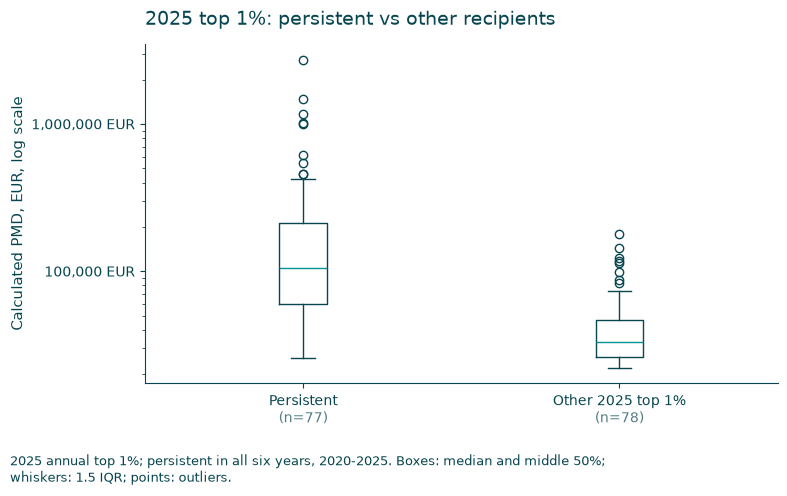

In [7]:
from chart_style import finish_chart, growth_boxplot, contrast_text

plot_data = [
    top_1_2025.loc[top_1_2025["group"] == "Returning top 1% (all years)", "calculated_pmd_eur"],
    top_1_2025.loc[top_1_2025["group"] == "Other 2025 top 1%", "calculated_pmd_eur"]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    plot_data,
    tick_labels=[f"Persistent\n(n={len(plot_data[0]):,})", f"Other 2025 top 1%\n(n={len(plot_data[1]):,})"],
    showfliers=True
)
plt.yscale("log")
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:,.0f} €"))
plt.title("2025 top 1%: persistent vs other recipients")
plt.ylabel("Calculated PMD, EUR, log scale")

finish_chart(plt.gcf(), '2025 annual top 1%; persistent in all six years, 2020-2025. Boxes: median and middle 50%; whiskers: 1.5 IQR; points: outliers.')


## Shares of recipients, funding and requests

Each share has its own denominator across all 2025 top-1% recipients. A funding share larger than the recipient share indicates greater average funding per recipient in that group, not a causal effect of persistence.

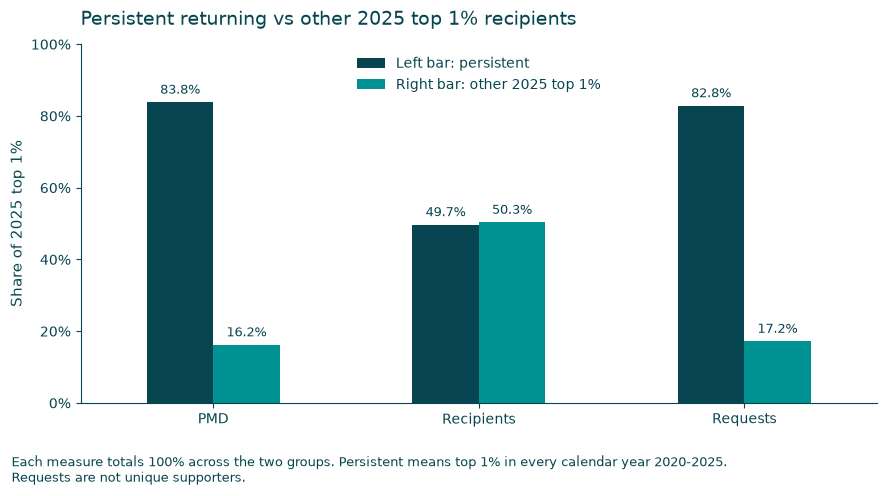

group,Returning top 1% (all years),Other 2025 top 1%
measure,,
PMD,0.838148,0.161852
Recipients,0.496774,0.503226
Requests,0.828369,0.171631


In [8]:
from chart_style import finish_chart, growth_boxplot, contrast_text

share_comparison = returning_vs_newcomers_summary[["group", "recipients", "total_pmd_eur", "total_requests"]].copy()
share_comparison["share_of_recipients"] = share_comparison["recipients"] / share_comparison["recipients"].sum()
share_comparison["share_of_pmd"] = share_comparison["total_pmd_eur"] / share_comparison["total_pmd_eur"].sum()
share_comparison["share_of_requests"] = share_comparison["total_requests"] / share_comparison["total_requests"].sum()

share_long = share_comparison.melt(
    id_vars="group",
    value_vars=["share_of_recipients", "share_of_pmd", "share_of_requests"],
    var_name="measure",
    value_name="share"
)

share_long["measure"] = share_long["measure"].replace({
    "share_of_recipients": "Recipients",
    "share_of_pmd": "PMD",
    "share_of_requests": "Requests"
})

pivot_share = share_long.pivot(index="measure", columns="group", values="share")

column_order = ["Returning top 1% (all years)", "Other 2025 top 1%"]
pivot_share = pivot_share[[col for col in column_order if col in pivot_share.columns]]

color_map = {
    "Returning top 1% (all years)": CHART_COLORS["primary"],
    "Other 2025 top 1%": CHART_COLORS["secondary"],
}

ax = pivot_share.plot(
    kind="bar",
    figsize=(9, 5),
    color=[color_map[col] for col in pivot_share.columns]
)

plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0%}"))
plt.title("Persistent returning vs other 2025 top 1% recipients")
plt.xlabel("")
plt.ylabel("Share of 2025 top 1%")
plt.xticks(rotation=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.1%}" for v in container.datavalues], padding=4, fontsize=9)
ax.set_ylim(0, 1)
ax.legend(["Left bar: persistent", "Right bar: other 2025 top 1%"], title=None)
finish_chart(plt.gcf(), 'Each measure totals 100% across the two groups. Persistent means top 1% in every calendar year 2020-2025. Requests are not unique supporters.')


display(pivot_share)


## Organization age in 2025

These tables and the chart use 2025 age, unlike notebook 05's age at first observed qualification. Counts use distinct recipient codes within each group, with Unknown age retained. Differences describe the two selected groups, not all organizations.

In [9]:
# Standardize age-group labels before grouping. This protects against
# Excel-style conversions such as 6-10 -> 10-Jun and 11-15 -> 15-Nov.
top_1_2025 = top_1_2025.copy()
top_1_2025["organization_age_group"] = (
    top_1_2025["organization_age_group"]
    .astype("string")
    .fillna("Unknown")
    .replace({
        "10-Jun": "6-10",
        "15-Nov": "11-15",
        "nan": "Unknown",
        "NaN": "Unknown",
        "<NA>": "Unknown",
    })
)

age_comparison = (
    top_1_2025
      .groupby(["group", "organization_age_group"], as_index=False)
      .agg(
          recipients=("recipient_code", "nunique"),
          total_pmd_eur=("calculated_pmd_eur", "sum"),
          total_requests=("requests", "sum")
      )
)

age_comparison["share_within_group"] = (
    age_comparison["recipients"]
    / age_comparison.groupby("group")["recipients"].transform("sum")
)

age_comparison


,group,organization_age_group,recipients,total_pmd_eur,total_requests,share_within_group
0,Other 2025 top 1%,0-5,17,917785.13,18094,0.217949
1,Other 2025 top 1%,11-15,7,378983.95,5764,0.089744
2,Other 2025 top 1%,16-20,4,161200.02,4305,0.051282
3,Other 2025 top 1%,21-25,2,80612.44,1593,0.025641
4,Other 2025 top 1%,26-30,6,165392.10,3514,0.076923
5,Other 2025 top 1%,6-10,18,568287.17,7644,0.230769
6,Other 2025 top 1%,Unknown,24,1117387.55,18883,0.307692
7,Returning top 1% (all years),0-5,2,330297.01,6740,0.025974
8,Returning top 1% (all years),11-15,25,7559958.07,115734,0.324675
9,Returning top 1% (all years),16-20,13,4151541.91,70452,0.168831


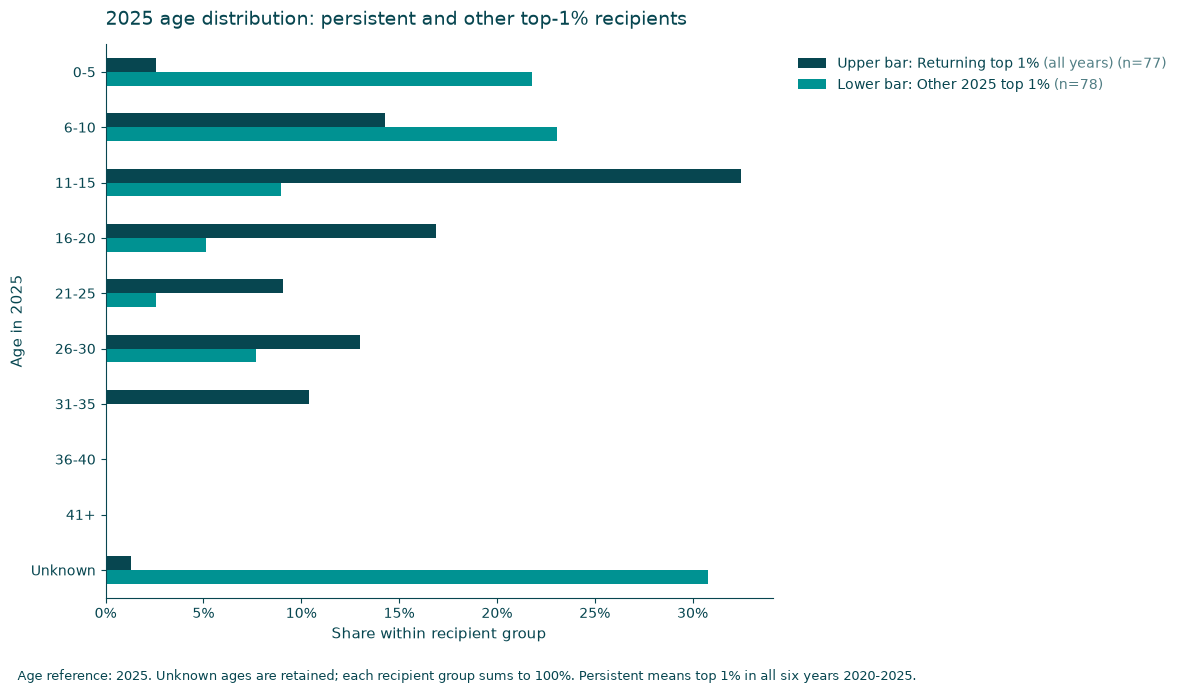

group,Returning top 1% (all years),Other 2025 top 1%
organization_age_group,,
0-5,0.025974,0.217949
6-10,0.142857,0.230769
11-15,0.324675,0.089744
16-20,0.168831,0.051282
21-25,0.090909,0.025641
26-30,0.129870,0.076923
31-35,0.103896,0.000000
36-40,0.000000,0.000000
41+,0.000000,0.000000


In [10]:
from chart_style import finish_chart, growth_boxplot, contrast_text

age_order = [
    "0-5", "6-10", "11-15", "16-20", "21-25",
    "26-30", "31-35", "36-40", "41+", "Unknown"
]

age_comparison["organization_age_group"] = (
    age_comparison["organization_age_group"]
    .astype("string")
    .replace({"10-Jun": "6-10", "15-Nov": "11-15"})
)

age_comparison["organization_age_group"] = pd.Categorical(
    age_comparison["organization_age_group"],
    categories=age_order,
    ordered=True
)

age_pivot = (
    age_comparison
    .pivot_table(
        index="group",
        columns="organization_age_group",
        values="share_within_group",
        aggfunc="sum",
        fill_value=0,
        observed=False
    )
)

age_pivot = age_pivot[[col for col in age_order if col in age_pivot.columns]]

age_plot = age_pivot.reindex(["Returning top 1% (all years)", "Other 2025 top 1%"]).T
ax = age_plot.plot.barh(figsize=(12, 7), color=[CHART_COLORS["primary"], CHART_COLORS["secondary"]])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set(title="2025 age distribution: persistent and other top-1% recipients", xlabel="Share within recipient group", ylabel="Age in 2025")
age_counts = top_1_2025.groupby("group")["recipient_code"].nunique()
ax.legend(labels=[f"{position}: {group} (n={age_counts.get(group, 0):,})" for position, group in zip(["Upper bar", "Lower bar"], age_plot.columns)], bbox_to_anchor=(1.02, 1), loc="upper left")
finish_chart(plt.gcf(), 'Age reference: 2025. Unknown ages are retained; each recipient group sums to 100%. Persistent means top 1% in all six years 2020-2025.')

display(age_plot)


## Reading the results together

Persistent and other recipients partition the 2025 top 1%. First-observed newcomers are a subset of other recipients, so the three labels must not be treated as three mutually exclusive groups.

[Previous notebook](05_top_1_persistent_recipients.ipynb) | [Next notebook](07_growth_drivers_analysis.ipynb) | [Reading guide](../README.md#reading-order)